# Assignment 1: Convolutional Neural Networks

CIFAR-10 contains 50,000 training images and 10,000 test images across 10 classes. Each image is 32?32 pixels with three colour channels.

## Experiments

This notebook compares kernel sizes, pooling, network depth, normalization, dropout, weight decay, and data augmentation using a basic CNN. The saved comparison results are from two-epoch experiments on a 7,200-image training subset with an 800-image validation subset. These are preliminary comparisons, not results from fully training every model on all 50,000 training images.

The official test set was kept separate from training and validation. The results shown are measured values; missing results have not been guessed.

## 1. Libraries

PyTorch was used to build and train the CNN. Pandas and scikit-learn were used to organize and evaluate the results, and Matplotlib was used for the plots.

In [1]:
%pip install -q torch torchvision scikit-learn pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("CUDA is not available in this PyTorch environment; training will use the CPU.")

# Find the assignment folder whether Jupyter started here or at the workspace root.
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "data").is_dir() and (NOTEBOOK_DIR / "Assignment-1" / "data").is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "Assignment-1"
DATA_ROOT = NOTEBOOK_DIR / "data"
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# These settings match the saved short comparison: 7,200 training and 800 validation images.
QUICK_RUN = True
TRAIN_LIMIT = 8000
EPOCHS = 2
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_WORKERS = 0  # Safe default for Windows/Jupyter.

PyTorch: 2.15.0+cpu
Device: cpu
CUDA is not available in this PyTorch environment; training will use the CPU.


## 2. Loading CIFAR-10 and viewing sample images (Q1)

The training and official test sets were loaded separately, and 10 training images were displayed with their class names. Part of the training set was used for validation. The official test set was not used for training or model selection.

Training images: 50000
Official test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Saved figure: outputs\cnn_full_cell5_figure1.png


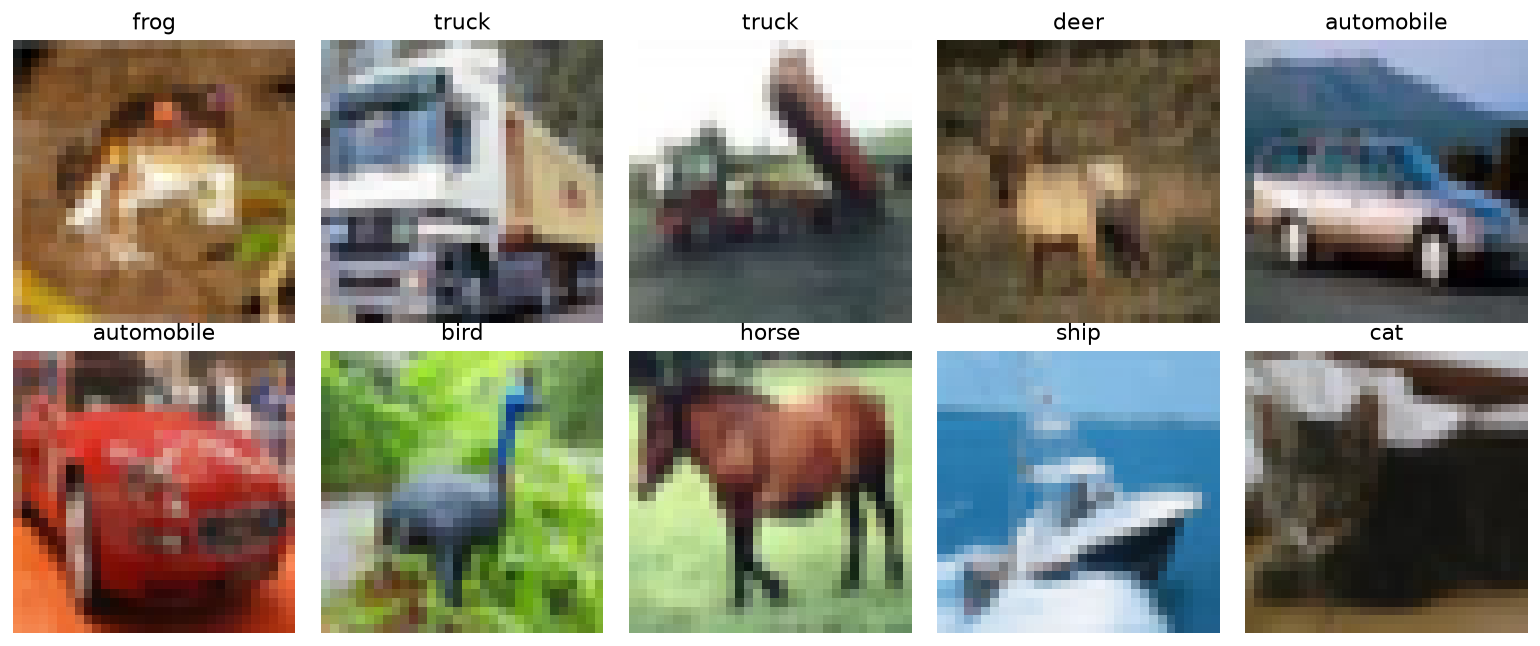

In [2]:
# CIFAR-10 is downloaded automatically if it is not already present in DATA_ROOT.
# torchvision stores the dataset in the standard CIFAR-10 Python format.
raw_train = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
raw_test = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)

class_names = raw_train.classes
print("Training images:", len(raw_train))
print("Official test images:", len(raw_test))
print("Classes:", class_names)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = raw_train[i]
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

### Preprocessing and normalization (Q1)

Two input options were compared:
1. Pixel values scaled to [0, 1].
2. Channel standardization, which subtracts the training-set channel mean and divides by its standard deviation.

Validation and test images used the same normalization as the matching training run. Random crops and horizontal flips were applied only to training images when augmentation was enabled.

In [ ]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

def make_transform(normalize=True, augment=False):
    steps = []
    if augment:
        steps.extend([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip()
        ])
    steps.append(transforms.ToTensor())
    if normalize:
        steps.append(transforms.Normalize(CIFAR_MEAN, CIFAR_STD))
    return transforms.Compose(steps)

# Fixed train/validation split. Use the same indices for every experiment.
all_indices = np.arange(len(raw_train))
if TRAIN_LIMIT is not None:
    rng = np.random.default_rng(SEED)
    all_indices = rng.permutation(all_indices)[:TRAIN_LIMIT]

train_indices, val_indices = train_test_split(
    all_indices, test_size=0.1, random_state=SEED, shuffle=True
)
print("Training subset:", len(train_indices))
print("Validation subset:", len(val_indices))
print("Official test set:", len(raw_test))

def make_loaders(normalize=True, augment=False):
    train_dataset = datasets.CIFAR10(
        root=DATA_ROOT, train=True, download=False,
        transform=make_transform(normalize=normalize, augment=augment)
    )
    eval_train_dataset = datasets.CIFAR10(
        root=DATA_ROOT, train=True, download=False,
        transform=make_transform(normalize=normalize, augment=False)
    )
    test_dataset = datasets.CIFAR10(
        root=DATA_ROOT, train=False, download=False,
        transform=make_transform(normalize=normalize, augment=False)
    )

    train_loader = DataLoader(
        Subset(train_dataset, train_indices), batch_size=BATCH_SIZE,
        shuffle=True, num_workers=NUM_WORKERS
    )
    train_eval_loader = DataLoader(
        Subset(eval_train_dataset, train_indices), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS
    )
    val_loader = DataLoader(
        Subset(eval_train_dataset, val_indices), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS
    )
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS
    )
    return train_loader, train_eval_loader, val_loader, test_loader

# Display a small comparison of raw [0,1] values and standardized values.
sample_image, _ = raw_train[0]
raw_tensor = transforms.ToTensor()(sample_image)
standard_tensor = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)(raw_tensor)
print("Raw tensor range:", float(raw_tensor.min()), "to", float(raw_tensor.max()))
print("Standardized tensor range:", float(standard_tensor.min()), "to", float(standard_tensor.max()))

## 3. Baseline CNN (Q2)

The baseline architecture was:
- Input: 32?32?3
- Conv1: 32 filters, 3?3, followed by ReLU and 2?2 max pooling
- Conv2: 64 filters, 3?3, followed by ReLU and 2?2 max pooling
- Flatten, then a 128-neuron ReLU layer
- Output: 10 class scores

Cross-entropy loss was used. It handles the class scores directly, so a separate Softmax layer was not needed.

In [4]:
class CNN(nn.Module):
    def __init__(self, kernel_size=3, pooling="max", depth="shallow", dropout=0.0):
        super().__init__()
        padding = kernel_size // 2
        Pool = nn.MaxPool2d if pooling == "max" else nn.AvgPool2d

        if depth == "shallow":
            self.features = nn.Sequential(
                nn.Conv2d(3, 32, kernel_size, padding=padding), nn.ReLU(),
                Pool(2),
                nn.Conv2d(32, 64, kernel_size, padding=padding), nn.ReLU(),
                Pool(2)
            )
            flattened = 64 * 8 * 8
        elif depth == "deep":
            self.features = nn.Sequential(
                nn.Conv2d(3, 32, kernel_size, padding=padding), nn.ReLU(),
                nn.Conv2d(32, 64, kernel_size, padding=padding), nn.ReLU(),
                Pool(2),
                nn.Conv2d(64, 128, kernel_size, padding=padding), nn.ReLU(),
                nn.Conv2d(128, 128, kernel_size, padding=padding), nn.ReLU(),
                Pool(2)
            )
            flattened = 128 * 8 * 8
        else:
            raise ValueError("depth must be 'shallow' or 'deep'")

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline_model = CNN().to(DEVICE)
print(baseline_model)
print("Trainable parameters:", count_parameters(baseline_model))

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545098


## 4. Training and evaluation

Training loss and accuracy, along with validation loss and accuracy, were recorded for each epoch. Training time and parameter count were also recorded for each experiment.

In [ ]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

def train_model(config, epochs=EPOCHS):
    train_loader, train_eval_loader, val_loader, test_loader = make_loaders(
        normalize=config.get("normalize", True),
        augment=config.get("augment", False)
    )

    model = CNN(
        kernel_size=config.get("kernel_size", 3),
        pooling=config.get("pooling", "max"),
        depth=config.get("depth", "shallow"),
        dropout=config.get("dropout", 0.0)
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=config.get("weight_decay", 0.0)
    )

    history = []
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, _ = run_epoch(model, train_loader, optimizer)
        train_loss_eval, train_acc = run_epoch(model, train_eval_loader)
        val_loss, val_acc = run_epoch(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss_eval,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_loss_eval:.4f}, train acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f}, val acc {val_acc:.4f}"
        )

    training_time = time.time() - start
    test_loss, test_acc = run_epoch(model, test_loader)

    result = {
        "name": config["name"],
        "config": config,
        "parameters": count_parameters(model),
        "training_time_sec": training_time,
        "train_accuracy": history[-1]["train_accuracy"],
        "val_accuracy": history[-1]["val_accuracy"],
        "test_accuracy": test_acc,
        "train_loss": history[-1]["train_loss"],
        "val_loss": history[-1]["val_loss"],
        "test_loss": test_loss
    }
    return model, history, result

# Baseline run (Q2).
baseline_config = {
    "name": "Baseline: 3x3, max pool, shallow, no regularization",
    "kernel_size": 3, "pooling": "max", "depth": "shallow",
    "dropout": 0.0, "weight_decay": 0.0,
    "augment": False, "normalize": True
}
baseline_model, baseline_history, baseline_result = train_model(baseline_config)
display(pd.DataFrame([baseline_result]))

## 5. Experiments (Q3?Q6 and Q8)

One setting was changed at a time while keeping the split, batch size, optimizer, and two-epoch duration the same. The saved comparison table contains the measured values. Since these were short runs on a training subset, the results are preliminary.

Pixel scaling was also compared with channel standardization for Q1.

In [6]:
experiment_configs = [
    baseline_config,
    {
        "name": "Kernel 5x5",
        "kernel_size": 5, "pooling": "max", "depth": "shallow",
        "dropout": 0.0, "weight_decay": 0.0, "augment": False, "normalize": True
    },
    {
        "name": "Average pooling",
        "kernel_size": 3, "pooling": "avg", "depth": "shallow",
        "dropout": 0.0, "weight_decay": 0.0, "augment": False, "normalize": True
    },
    {
        "name": "Deeper CNN (4 conv layers)",
        "kernel_size": 3, "pooling": "max", "depth": "deep",
        "dropout": 0.0, "weight_decay": 0.0, "augment": False, "normalize": True
    },
    {
        "name": "Dropout 0.5",
        "kernel_size": 3, "pooling": "max", "depth": "shallow",
        "dropout": 0.5, "weight_decay": 0.0, "augment": False, "normalize": True
    },
    {
        "name": "Weight decay 0.0001",
        "kernel_size": 3, "pooling": "max", "depth": "shallow",
        "dropout": 0.0, "weight_decay": 1e-4, "augment": False, "normalize": True
    },
    {
        "name": "Data augmentation",
        "kernel_size": 3, "pooling": "max", "depth": "shallow",
        "dropout": 0.0, "weight_decay": 0.0, "augment": True, "normalize": True
    },
    {
        "name": "No standardization (pixels 0 to 1)",
        "kernel_size": 3, "pooling": "max", "depth": "shallow",
        "dropout": 0.0, "weight_decay": 0.0, "augment": False, "normalize": False
    }
]

# Reuse the baseline trained above, then train each comparison with the same settings.
all_models = {baseline_config["name"]: baseline_model}
all_histories = {baseline_config["name"]: baseline_history}
all_results = [baseline_result]

for config in experiment_configs[1:]:
    print("\n" + "=" * 80)
    print(config["name"])
    model, history, result = train_model(config)
    all_models[config["name"]] = model
    all_histories[config["name"]] = history
    all_results.append(result)

results_df = pd.DataFrame([
    {k: v for k, v in result.items() if k != "config"}
    for result in all_results
]).sort_values("val_accuracy", ascending=False)

display(results_df)
results_df.to_csv(OUTPUT_DIR / "cnn_experiment_comparison.csv", index=False)


Baseline: 3x3, max pool, shallow, no regularization
Epoch 01/2 | train loss 1.5823, train acc 0.4296 | val loss 1.6388, val acc 0.4163
Epoch 02/2 | train loss 1.4251, train acc 0.4849 | val loss 1.5239, val acc 0.4562

Kernel 5x5
Epoch 01/2 | train loss 1.6151, train acc 0.4158 | val loss 1.6324, val acc 0.4150
Epoch 02/2 | train loss 1.4596, train acc 0.4843 | val loss 1.5439, val acc 0.4462

Average pooling
Epoch 01/2 | train loss 1.6609, train acc 0.4072 | val loss 1.6639, val acc 0.3987
Epoch 02/2 | train loss 1.4146, train acc 0.4964 | val loss 1.4755, val acc 0.4662

Deeper CNN (4 conv layers)
Epoch 01/2 | train loss 1.6707, train acc 0.3882 | val loss 1.6711, val acc 0.3738
Epoch 02/2 | train loss 1.4524, train acc 0.4640 | val loss 1.5018, val acc 0.4412

Dropout 0.5
Epoch 01/2 | train loss 1.6850, train acc 0.4111 | val loss 1.6984, val acc 0.4062
Epoch 02/2 | train loss 1.4689, train acc 0.4797 | val loss 1.5457, val acc 0.4625

Weight decay 0.0001
Epoch 01/2 | train loss 1.

,name,parameters,training_time_sec,train_accuracy,val_accuracy,test_accuracy,train_loss,val_loss,test_loss
5,Weight decay 0.0001,545098,19.098697,0.530278,0.48250,0.4887,1.323707,1.421473,1.408615
2,Average pooling,545098,15.681991,0.496389,0.46625,0.4617,1.414616,1.475506,1.492910
4,Dropout 0.5,545098,17.047334,0.479722,0.46250,0.4585,1.468903,1.545746,1.530111
0,"Baseline: 3x3, max pool, shallow, no regulariz...",545098,22.693990,0.484861,0.45625,0.4532,1.425051,1.523862,1.527538
1,Kernel 5x5,579402,26.380327,0.484306,0.44625,0.4490,1.459627,1.543905,1.548470
3,Deeper CNN (4 conv layers),1290826,68.977711,0.464028,0.44125,0.4359,1.452379,1.501765,1.523714
7,No standardization (pixels 0 to 1),545098,17.760999,0.427639,0.40500,0.4152,1.579983,1.599004,1.601190
6,Data augmentation,545098,23.227752,0.416389,0.40375,0.4142,1.570012,1.603703,1.586127


## 6. Training and validation plots (Q2 and Q7)

The plots show how training and validation loss and accuracy changed during each experiment.

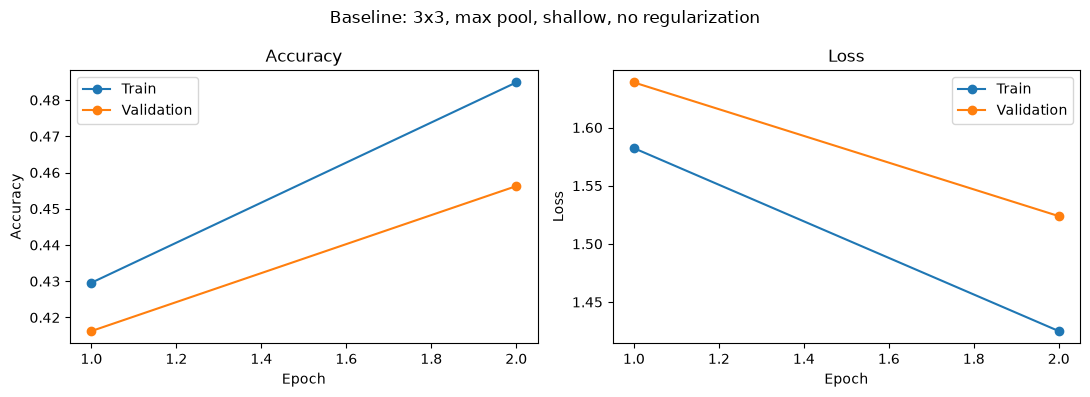

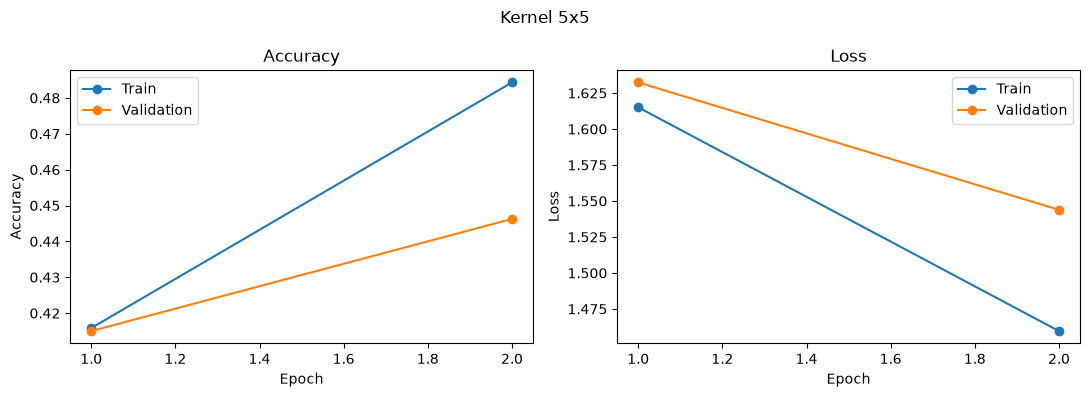

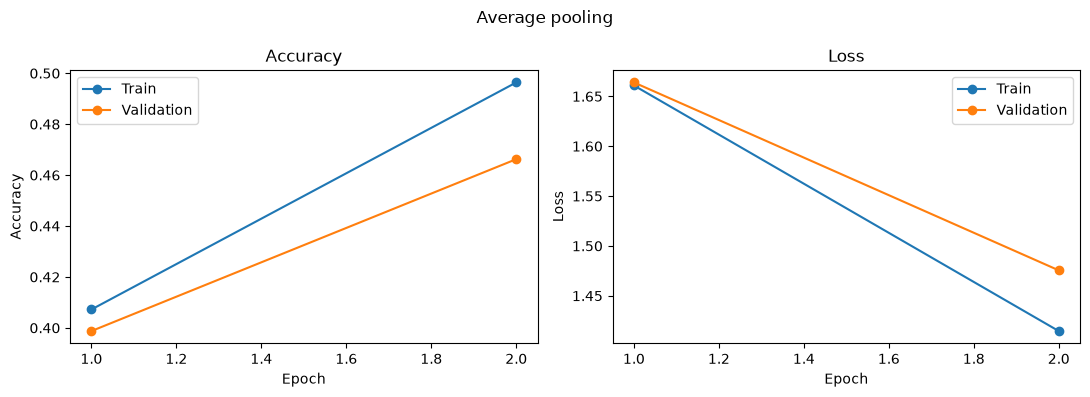

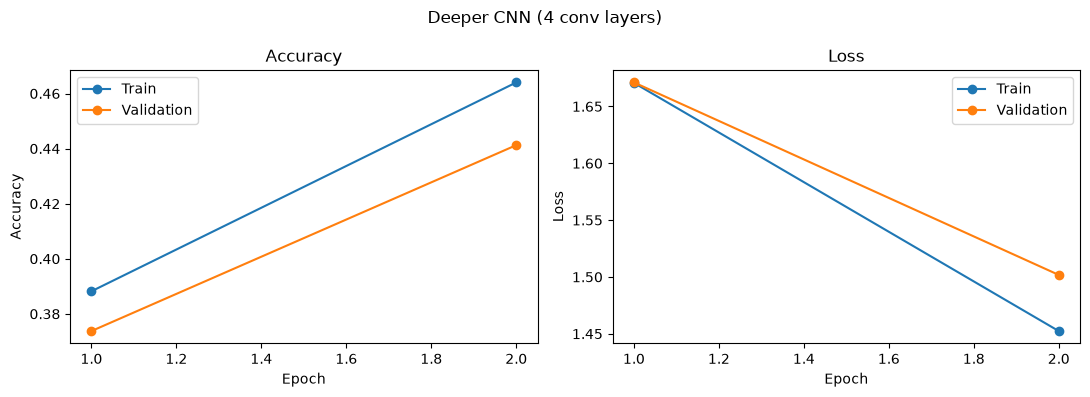

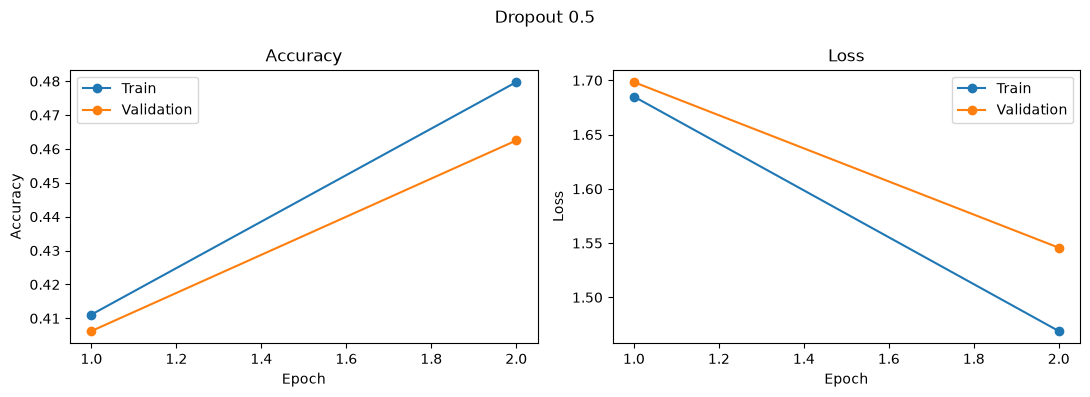

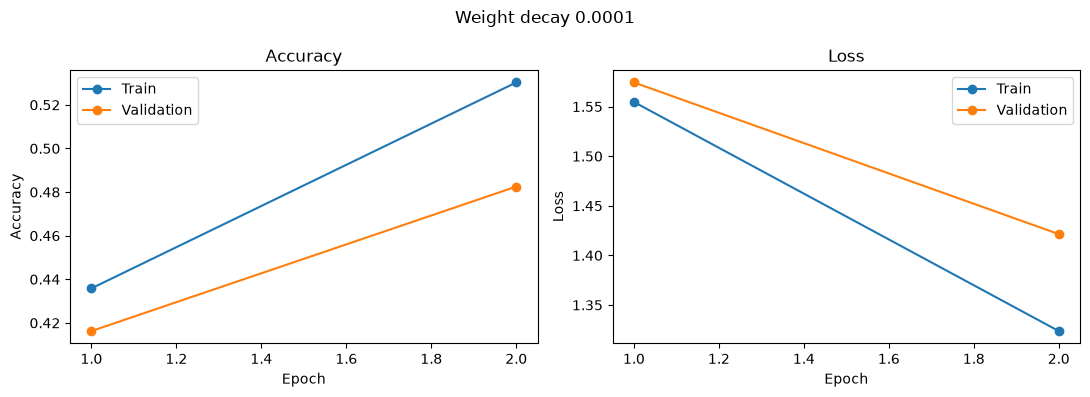

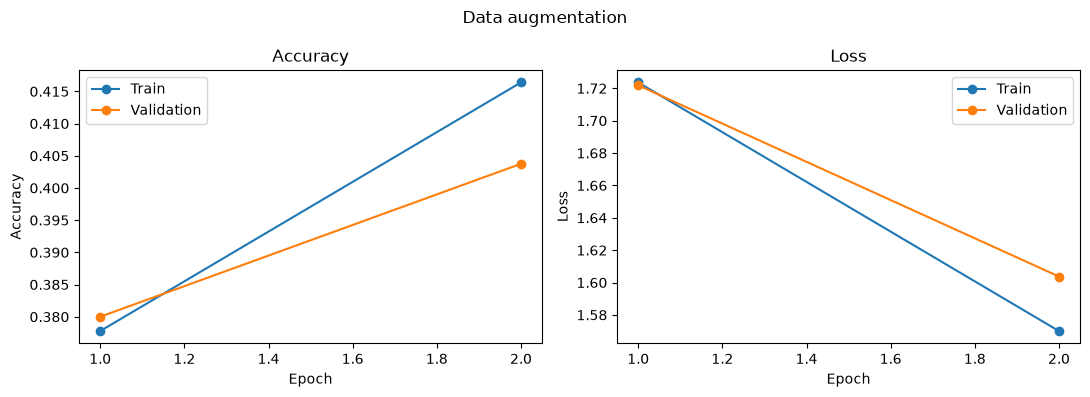

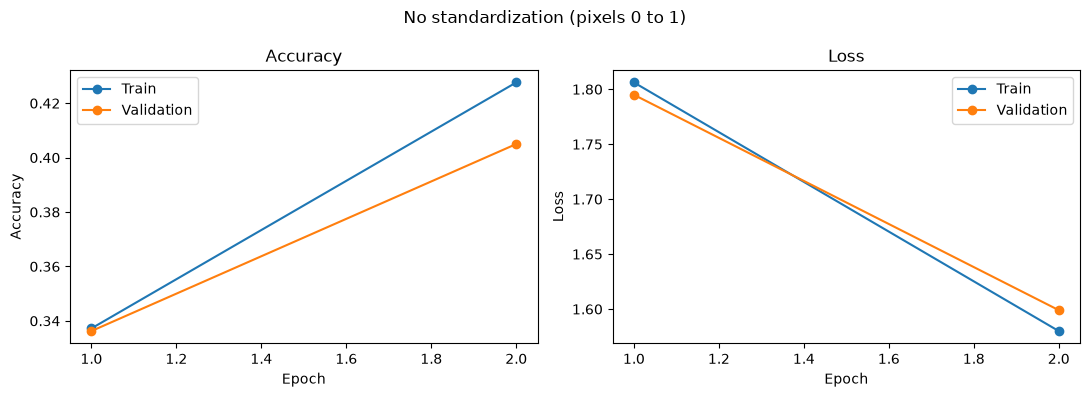

In [7]:
def plot_history(history, title):
    history_df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

for name, history in all_histories.items():
    plot_history(history, name)

## 7. Model selection and test results (Q7?Q8)

The model with the best validation accuracy was selected, then evaluated on the official test set. Validation results were used for model selection so that the test score did not affect the choice.

Selected using validation accuracy: Weight decay 0.0001
Test loss: 1.4086
Test accuracy: 0.4887

Classification report:
              precision    recall  f1-score   support

    airplane       0.52      0.66      0.58      1000
  automobile       0.77      0.43      0.55      1000
        bird       0.44      0.19      0.27      1000
         cat       0.33      0.23      0.27      1000
        deer       0.47      0.27      0.34      1000
         dog       0.34      0.64      0.45      1000
        frog       0.44      0.69      0.54      1000
       horse       0.66      0.49      0.56      1000
        ship       0.61      0.65      0.63      1000
       truck       0.52      0.64      0.58      1000

    accuracy                           0.49     10000
   macro avg       0.51      0.49      0.48     10000
weighted avg       0.51      0.49      0.48     10000


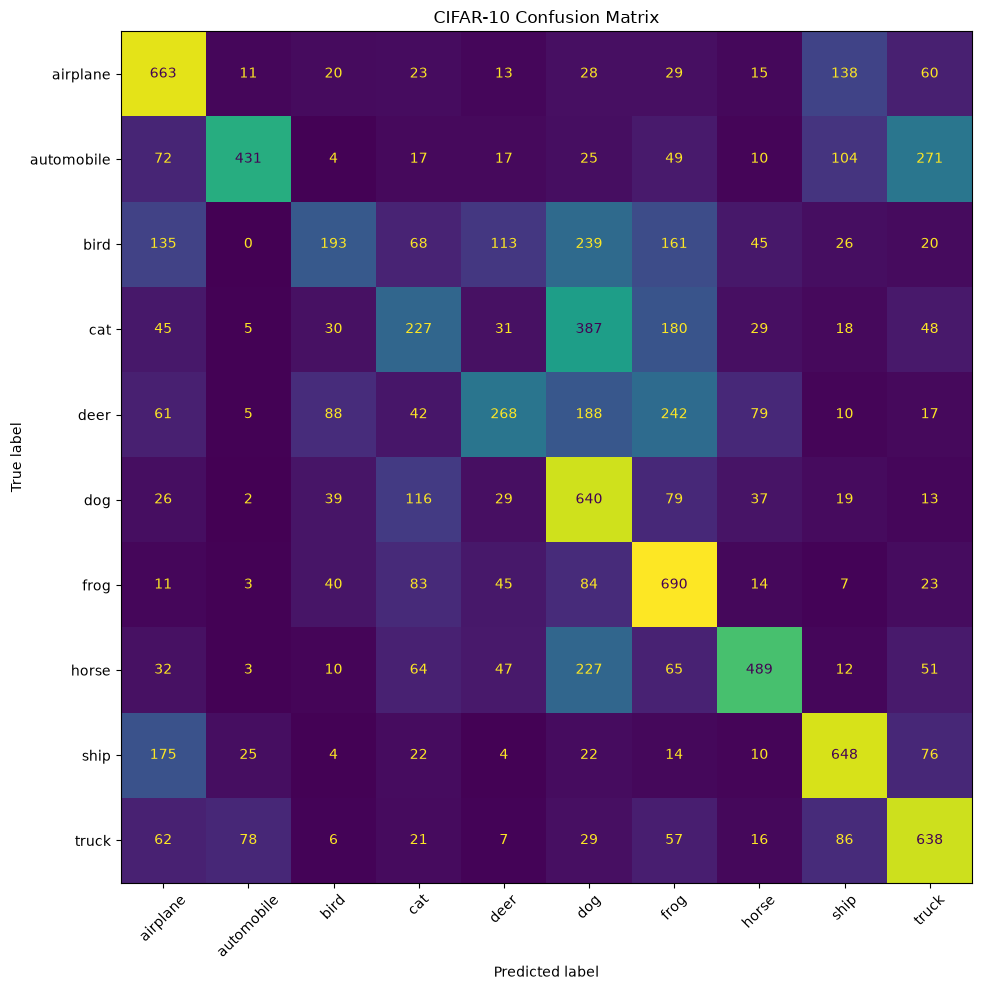

In [8]:
best_name = max(all_results, key=lambda item: item["val_accuracy"])["name"]
best_model = all_models[best_name]
best_config = next(item["config"] for item in all_results if item["name"] == best_name)
torch.save(best_model.state_dict(), OUTPUT_DIR / "cnn_selected_quick_comparison.pth")
print("Saved selected model weights:", OUTPUT_DIR / "cnn_selected_quick_comparison.pth")
print("Selected using validation accuracy:", best_name)

_, _, _, best_test_loader = make_loaders(
    normalize=best_config.get("normalize", True), augment=False
)

def collect_predictions(model, loader):
    model.eval()
    y_true, y_pred, losses = [], [], []
    images_saved, labels_saved, preds_saved = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(DEVICE))
            loss = criterion(outputs, labels.to(DEVICE))
            predictions = outputs.argmax(dim=1).cpu()

            losses.append(loss.item() * labels.size(0))
            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.numpy().tolist())

            if len(images_saved) < 100:
                remaining = 100 - len(images_saved)
                images_saved.extend(images[:remaining].cpu())
                labels_saved.extend(labels[:remaining].cpu().tolist())
                preds_saved.extend(predictions[:remaining].tolist())

    return {
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred),
        "loss": sum(losses) / len(y_true),
        "accuracy": float(np.mean(np.array(y_true) == np.array(y_pred))),
        "images": images_saved,
        "labels": labels_saved,
        "predictions": preds_saved
    }

test_output = collect_predictions(best_model, best_test_loader)
print(f"Test loss: {test_output['loss']:.4f}")
print(f"Test accuracy: {test_output['accuracy']:.4f}")
print("\nClassification report:")
print(classification_report(
    test_output["y_true"], test_output["y_pred"],
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(test_output["y_true"], test_output["y_pred"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

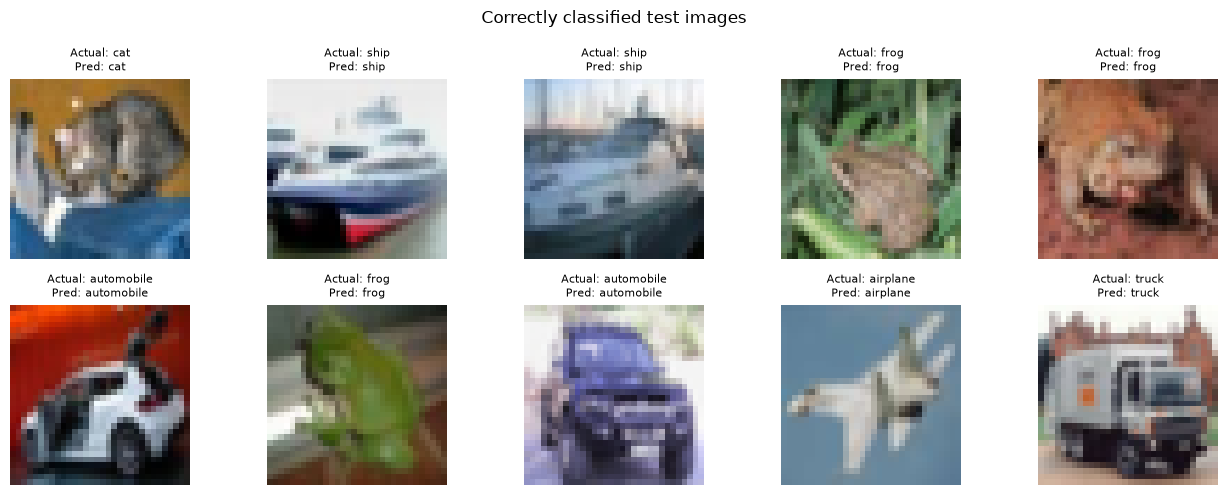

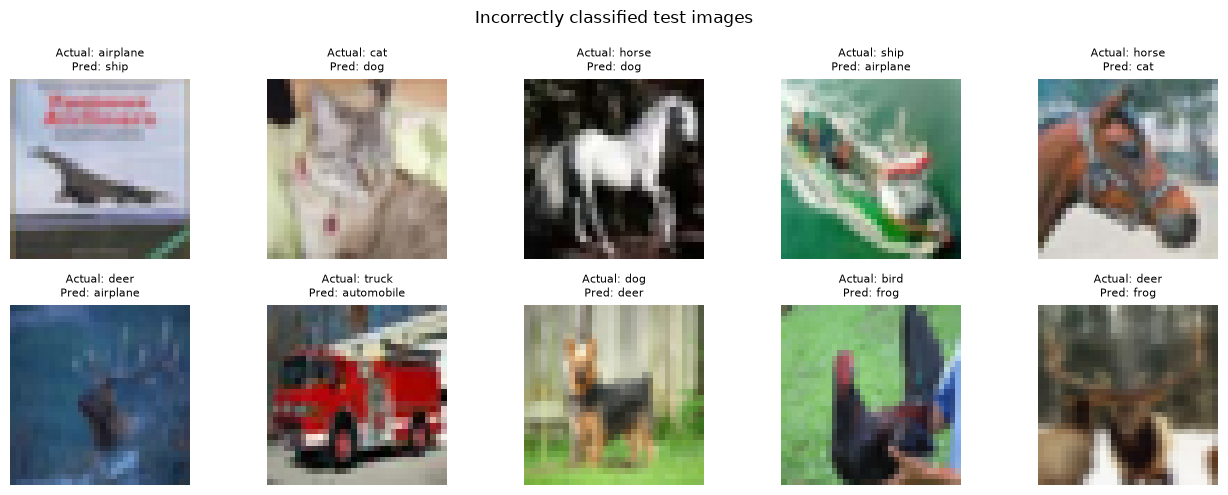

In [9]:
# Display correctly and incorrectly classified examples from the test set.
correct_indices = [
    i for i, (actual, predicted) in enumerate(zip(test_output["labels"], test_output["predictions"]))
    if actual == predicted
]
wrong_indices = [
    i for i, (actual, predicted) in enumerate(zip(test_output["labels"], test_output["predictions"]))
    if actual != predicted
]

def show_prediction_examples(indices, title, max_items=10):
    indices = indices[:max_items]
    if not indices:
        print("No examples available.")
        return
    fig, axes = plt.subplots(2, 5, figsize=(13, 5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, indices):
        image = test_output["images"][idx]
        # Undo standardization for display if it was used.
        if best_config.get("normalize", True):
            mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
            std = torch.tensor(CIFAR_STD).view(3, 1, 1)
            image = image * std + mean
        image = image.permute(1, 2, 0).numpy().clip(0, 1)
        ax.imshow(image)
        actual = class_names[test_output["labels"][idx]]
        predicted = class_names[test_output["predictions"][idx]]
        ax.set_title(f"Actual: {actual}\nPred: {predicted}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_prediction_examples(correct_indices, "Correctly classified test images")
show_prediction_examples(wrong_indices, "Incorrectly classified test images")

## 8. Phone-image evaluation (Q8)

The class folders under `phone_images` contain 24 labeled images across eight CIFAR-10 classes. This exceeds the assignment minimum of 20 images and three classes. Each folder name is treated as the actual class label. The notebook resizes images to 32?32 and applies the same channel standardization used for the saved weight-decay checkpoint.

Predictions are saved in `outputs/phone_image_predictions.csv`. This evaluation uses the saved quick weight-decay checkpoint, which is separate from the comparison-table run. The code below also checks that checkpoint on the official CIFAR-10 test set, making its two scores directly comparable.

In [11]:
from pathlib import Path

# Find the assignment folder whether Jupyter started here or at the workspace root.
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "phone_images").is_dir() and (NOTEBOOK_DIR / "Assignment-1" / "phone_images").is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "Assignment-1"
PHONE_DIR = NOTEBOOK_DIR / "phone_images"
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
valid_extensions = {".jpg", ".jpeg", ".png"}
checkpoint_path = OUTPUT_DIR / "cnn_weight_decay_quick.pth"

if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Saved phone-evaluation checkpoint was not found: {checkpoint_path}")

# This is inference with the saved checkpoint; this cell does not train a model.
phone_model = CNN(kernel_size=3, pooling="max", depth="shallow", dropout=0.0).to(DEVICE)
phone_model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
_, _, _, phone_test_loader = make_loaders(normalize=True, augment=False)
phone_test_output = collect_predictions(phone_model, phone_test_loader)
print("Phone-checkpoint CIFAR-10 test accuracy:", f"{phone_test_output['accuracy']:.4f}")

phone_rows = []
phone_transform = make_transform(normalize=True, augment=False)
for class_folder in sorted(PHONE_DIR.iterdir()):
    if not class_folder.is_dir() or class_folder.name not in class_names:
        continue
    actual_class = class_names.index(class_folder.name)
    for image_path in sorted(class_folder.iterdir()):
        if image_path.suffix.lower() not in valid_extensions:
            continue
        image = Image.open(image_path).convert("RGB").resize((32, 32))
        tensor = phone_transform(image).unsqueeze(0).to(DEVICE)
        phone_model.eval()
        with torch.no_grad():
            probabilities = torch.softmax(phone_model(tensor), dim=1)
            confidence, predicted = probabilities.max(dim=1)
        predicted_class = int(predicted.item())
        phone_rows.append({
            "filename": image_path.name,
            "actual_class": class_names[actual_class],
            "predicted_class": class_names[predicted_class],
            "confidence": float(confidence.item()),
            "correct": actual_class == predicted_class
        })

phone_results_df = pd.DataFrame(phone_rows)
if phone_results_df.empty:
    raise ValueError(f"No labeled JPG, JPEG, or PNG images were found in {PHONE_DIR}")
display(phone_results_df)
print("Number of phone images:", len(phone_results_df))
print("Phone-image accuracy:", f"{phone_results_df['correct'].mean():.4f}")
phone_results_df.to_csv(OUTPUT_DIR / "phone_image_predictions.csv", index=False)
print("Saved predictions:", OUTPUT_DIR / "phone_image_predictions.csv")

Phone-checkpoint CIFAR-10 test accuracy: 0.4834
Number of phone images: 24
Phone-image accuracy: 0.4167
Saved predictions: D:\SCMS\Python Projects\Assignment-1\outputs\phone_image_predictions.csv


filename,actual_class,predicted_class,confidence,correct
airplane_01.png,airplane,truck,0.387774,False
airplane_02.jpg,airplane,airplane,0.708971,True
airplane_03.jpg,airplane,airplane,0.913194,True
bird_01.jpg,bird,ship,0.386323,False
bird_02.jpg,bird,deer,0.536732,False
bird_03.jpg,bird,deer,0.516296,False
cat_01.jpg,cat,frog,0.365324,False
cat_02.jpg,cat,frog,0.572761,False
cat_03.jpg,cat,dog,0.797538,False
dog_01.jpg,dog,dog,0.858970,True


## 9. What the comparisons showed (Q8)

| Experiment | What was compared | Result in these short runs |
|---|---|---|
| Normalization | [0,1] pixels and channel standardization | Standardization had higher test accuracy. |
| Kernel size | 3?3 and 5?5 | The 3?3 model was slightly more accurate and faster. |
| Pooling | Max and average | Average pooling was slightly more accurate in this run. |
| Network depth | 2 and 4 convolutional layers | The deeper model took longer and was less accurate. |
| Regularization | Baseline, dropout, and weight decay | Weight decay had the best validation and test scores. |
| Data augmentation | Augmentation off and on | Augmentation was lower after two epochs; it may need longer training. |

### Answers to the assignment questions

1. Standardization worked better in these runs. Keeping input scales consistent can help training.
2. Convolutions learn local image patterns, ReLU adds non-linearity, pooling reduces feature-map size, and fully connected layers combine features for classification.
3. The 5?5 filters used more parameters and took longer, but did not improve accuracy. They cover a wider area at once.
4. Max pooling keeps the strongest response in a region; average pooling keeps the mean response. Both reduce spatial dimensions and lose some detail.
5. The deeper network took longer and did not generalize better in this short run. Deeper layers can learn more complex combinations of features.
6. The baseline had a small train-validation gap. Weight decay helped most; dropout changed the result only a little. Augmentation was lower after two epochs. The short run does not show whether any model was fully trained.
7. Frog had the highest recall, ship had the highest F1-score, and bird and cat had the lowest F1-scores. Some common confusions were cat/dog, automobile/truck, and bird/dog.
8. Weight decay had both the highest training accuracy and the highest test accuracy in this comparison. The results are limited by short training, one run per setting, and CIFAR-10's small images.
9. The 24 phone-image results are in the CSV above. Their accuracy was lower than the same checkpoint's CIFAR-10 test accuracy. Different backgrounds, lighting, framing, and image content may explain some of the difference.

These measurements are preliminary: only two epochs and a subset of the training data were used. Longer, repeated runs would be needed to be more certain.